## Exploring school closures

In [1]:
import pandas as pd

df = pd.read_csv('data/education_entities.csv')
df.head()

,ISDCode,ISDOfficialName,DistrictCode,DistrictOfficialName,DistrictType,DistrictTypeName,DistrictCommonName,EntityCode,EntityOfficialName,AgreementNumber,...,EntityPhysicalZip4,EntityMailingStreet,EntityMailingCity,EntityMailingState,EntityMailingZip4,EarlyMiddleCollege,SEEType,HeadStartGrantee,SchoolEmphasis,ESSASupportStatus
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8549,A&J Romper Room Educ. Center,820108549.0,...,482032440.0,17526 Riopelle,Detroit,MI,482032440,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9732,Aabizikaawin Alternative,370109732.0,...,488588970.0,7070 EAST BROADWAY RD,MOUNT PLEASANT,MI,488588970,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8170,Abundant Life Academy,781108170.0,...,488672318.0,208 W. Oliver Street,Owosso,MI,488672318,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8836,Abyssinia School of Explorers,632508836.0,...,482373051.0,20820 Greenfield Road,Oak Park,MI,482373051,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7396,"Academy of Excellence, Inc.",820107396.0,...,482053254.0,11560 EAST MCNICHOLS RD,DETROIT,MI,482053254,NaN,NaN,NaN,NaN,NaN


In [2]:
len(df)

8531

In [7]:
#breakdown of type of entities
df['EntityTypeName'].value_counts()

EntityTypeName
LEA School                                  4671
Nonpublic School                            1555
LEA Unique Education Provider                772
PSA School                                   642
LEA Non-Instructional Ancillary Facility     304
ISD Unique Education Provider                228
ISD School                                   184
ISD Non-Instructional Ancillary Facility      82
State Unique Education Provider               62
State School                                  19
PSA Unique Education Provider                 12
Name: count, dtype: int64

In [8]:
#How many entities have a closure date listed?
len(df[df['EntityCloseDate'].notna()])

3843

In [4]:
#how many have a closure date since 2000?

#turn date into a datetime object
have_close_date = df[df['EntityCloseDate'].notna()]
have_close_date['EntityCloseDate'] = pd.to_datetime(have_close_date['EntityCloseDate'], errors='coerce')

closed_since_2000 = have_close_date[have_close_date['EntityCloseDate'] >= '2000-01-01']

In [5]:
closed_since_2000['CloseYear'] = closed_since_2000['EntityCloseDate'].dt.year
closures_by_year = closed_since_2000.groupby('CloseYear').size()

In [6]:
len(closed_since_2000)

3248

<BarContainer object of 27 artists>

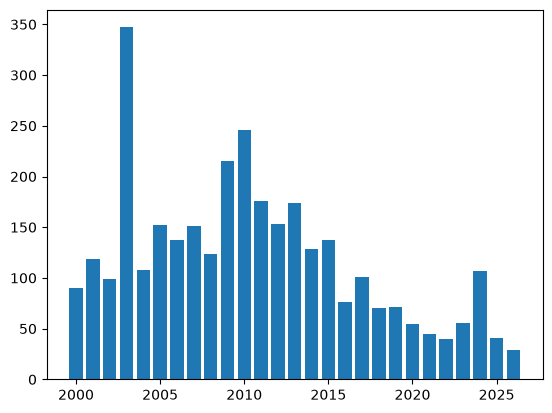

In [7]:
import matplotlib.pyplot as plt
plt.bar(closures_by_year.index, closures_by_year.values)

How do the closures break down by entity type?

In [8]:
closed_since_2000['EntityTypeName'].value_counts()

EntityTypeName
LEA School                                  1645
Nonpublic School                             813
LEA Unique Education Provider                296
PSA School                                   256
ISD Unique Education Provider                 73
ISD School                                    59
LEA Non-Instructional Ancillary Facility      46
State Unique Education Provider               29
ISD Non-Instructional Ancillary Facility      13
PSA Unique Education Provider                 10
State School                                   8
Name: count, dtype: int64

Let's filter to just schools (get rid of unique education providers and ancillary facilities)

In [9]:
select_types = ['LEA School', 'Nonpublic School', 
                'PSA School', 'ISD School', 'State School']
selected_closed_since_2000 = closed_since_2000[closed_since_2000['EntityTypeName'].isin(select_types)]
len(selected_closed_since_2000)

2781

<Axes: xlabel='CloseYear'>

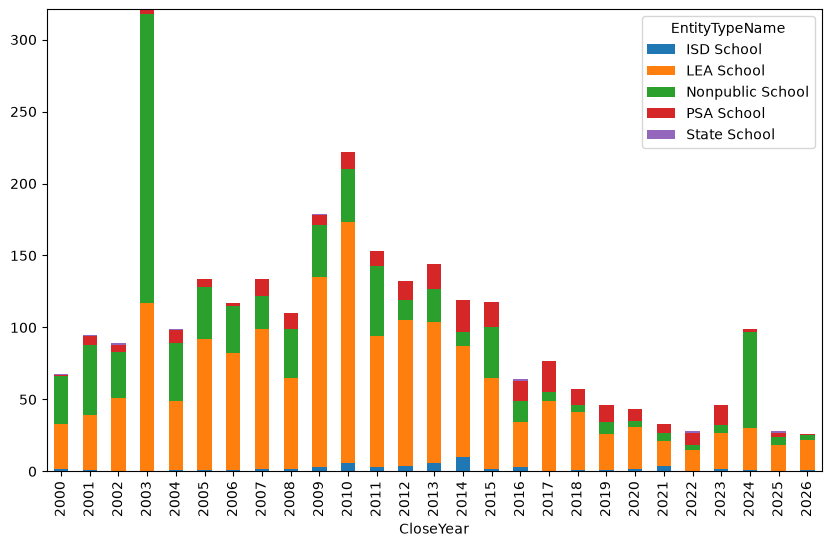

In [10]:
selected_closed_since_2000.groupby(['CloseYear', 'EntityTypeName']).size().unstack().plot(kind='bar', stacked=True, figsize=(10,6))

**What % of each school type closed since 2000?**

In [11]:
all_schools = df[df['EntityTypeName'].isin(select_types)]
len(all_schools)

7071

In [12]:
#get rid of schools closed before 2000
all_schools = all_schools[all_schools['EntityCloseDate'].isna() | (pd.to_datetime(all_schools['EntityCloseDate'], errors='coerce') >= '2000-01-01')]

In [13]:
all_schools['ClosedSince2000'] = all_schools['EntityCloseDate'].notna() & (pd.to_datetime(all_schools['EntityCloseDate'], errors='coerce') >= '2000-01-01')
all_schools['ClosedSince2000'].value_counts()

ClosedSince2000
False    3935
True     2781
Name: count, dtype: int64

In [23]:
all_schools[:100].to_csv('data/sample_schools.csv')

In [14]:
all_schools_closed = all_schools.groupby(['EntityTypeName', 'ClosedSince2000']).size().reset_index()
all_schools_closed_pivot = all_schools_closed.pivot(index='EntityTypeName', columns='ClosedSince2000', values=0).fillna(0).reset_index()
all_schools_closed_pivot.columns = ['Type', 'NotClosed', 'ClosedSince2000']
all_schools_closed_pivot['Total'] = all_schools_closed_pivot['NotClosed'] + all_schools_closed_pivot['ClosedSince2000']
all_schools_closed_pivot['PercentClosed'] = all_schools_closed_pivot['ClosedSince2000'] / all_schools_closed_pivot['Total'] * 100

In [15]:
all_schools_closed_pivot

,Type,NotClosed,ClosedSince2000,Total,PercentClosed
0,ISD School,119,59,178,33.146067
1,LEA School,2814,1645,4459,36.891680
2,Nonpublic School,623,813,1436,56.615599
3,PSA School,376,256,632,40.506329
4,State School,3,8,11,72.727273


### Looking at some key factors
 - location
 - location type (urban, rural, suburban)
 - Grade configuration

In [16]:
#normalize city column
city_df = all_schools.copy()
city_df['EntityMailingCity'] = city_df['EntityMailingCity'].str.strip().str.title()
city_df['EntityMailingCity'].value_counts().head(5)

EntityMailingCity
Detroit         640
Grand Rapids    296
Flint           147
Saginaw         113
Lansing         109
Name: count, dtype: int64

In [17]:
#look at closures by city and school type
closures_by_city_type = city_df[['EntityMailingCity', 'EntityTypeName', 'ClosedSince2000']].groupby(['EntityMailingCity', 'EntityTypeName']).size().unstack().fillna(0).reset_index()

In [18]:
closures_by_city_type['Total'] = closures_by_city_type['ISD School'] + closures_by_city_type['LEA School'] + closures_by_city_type['Nonpublic School'] + closures_by_city_type['PSA School'] + closures_by_city_type['State School']
closures_by_city_type.sort_values(by='Total', ascending=False).head(10)

EntityTypeName,EntityMailingCity,ISD School,LEA School,Nonpublic School,PSA School,State School,Total
175,Detroit,1.0,337.0,124.0,176.0,2.0,640.0
263,Grand Rapids,7.0,202.0,56.0,31.0,0.0,296.0
231,Flint,3.0,102.0,22.0,19.0,1.0,147.0
575,Saginaw,6.0,69.0,25.0,13.0,0.0,113.0
369,Lansing,4.0,68.0,24.0,13.0,0.0,109.0
14,Ann Arbor,8.0,35.0,41.0,6.0,0.0,90.0
342,Kalamazoo,5.0,49.0,23.0,10.0,0.0,87.0
458,Muskegon,3.0,59.0,12.0,12.0,0.0,86.0
675,Warren,2.0,47.0,16.0,12.0,0.0,77.0
711,Ypsilanti,2.0,47.0,11.0,12.0,0.0,72.0


In [19]:
closures_by_city_type['PublicClosures'] = closures_by_city_type['ISD School'] + closures_by_city_type['LEA School'] + closures_by_city_type['State School']
closures_by_city_type['CharterClosures'] = closures_by_city_type['PSA School']
closures_by_city_type['PrivateClosures'] = closures_by_city_type['Nonpublic School']

public_private_compare = closures_by_city_type[['EntityMailingCity', 'PublicClosures', 'CharterClosures', 'PrivateClosures', 'Total']].copy()
public_private_compare.rename(columns={'EntityMailingCity': 'City'}, inplace=True)
public_private_compare

EntityTypeName,City,PublicClosures,CharterClosures,PrivateClosures,Total
0,Ada,6.0,0.0,4.0,10.0
1,Addison,7.0,0.0,1.0,8.0
2,Adrian,21.0,0.0,7.0,28.0
3,Akron,1.0,0.0,0.0,1.0
4,Alanson,1.0,0.0,0.0,1.0
...,...,...,...,...,...
708,Wyandotte,11.0,0.0,6.0,17.0
709,Wyoming,26.0,2.0,16.0,44.0
710,Yale,4.0,0.0,0.0,4.0
711,Ypsilanti,49.0,12.0,11.0,72.0


In [20]:
public_private_compare.to_csv('data/closures_by_city_type.csv', index=False)

In [21]:
#load city geojson
import geopandas as gpd
cities_geo = gpd.read_file('data/city.geojson')
cities_geo.plot()

ModuleNotFoundError: No module named 'geopandas'

In [ ]:
#merge with closures data on city column
cities_geo.head()

,OBJECTID,FIPSCode,Name,MapLayout,FIPSNum,Label,Type,MGFVersion,Peninsula,Shape__Area,Shape__Length,geometry
0,1121,24740,Ecorse,landscape,24740,City of Ecorse,City,V26,Lower,7.099453e+06,15840.554312,"MULTIPOLYGON (((-83.13932 42.2377, -83.13952 4..."
1,1122,14820,Charlotte,landscape,14820,City of Charlotte,City,V26,Lower,1.650829e+07,45268.904596,"MULTIPOLYGON (((-84.81252 42.55671, -84.81251 ..."
2,1123,39540,Howell,portrait,39540,City of Howell,City,V26,Lower,1.326661e+07,33695.915920,"MULTIPOLYGON (((-83.91209 42.59985, -83.91211 ..."
3,1124,04740,Bad Axe,portrait,4740,City of Bad Axe,City,V26,Lower,6.226524e+06,26692.857325,"MULTIPOLYGON (((-82.9947 43.80955, -82.9947 43..."
4,1125,49700,Luna Pier,portrait,49700,City of Luna Pier,City,V26,Lower,3.834812e+06,16109.614509,"POLYGON ((-83.41958 41.82131, -83.42023 41.821..."


<Axes: >

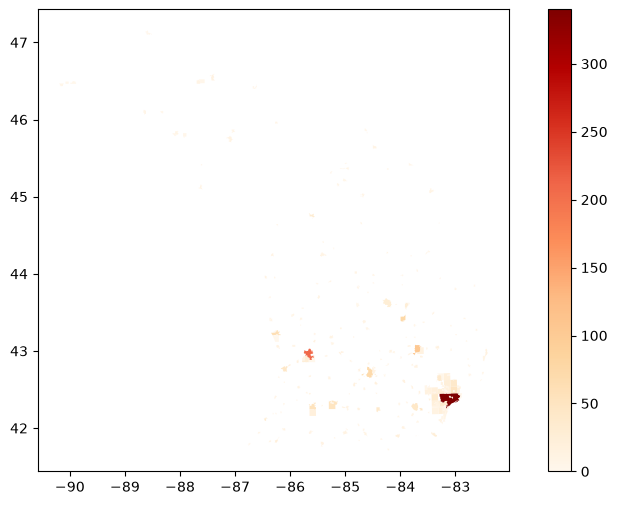

In [ ]:
merged_geo = pd.merge(cities_geo, public_private_compare, left_on='Name', right_on='City', how='inner')
merged_geo.plot(column='PublicClosures', cmap='OrRd', legend=True, figsize=(10,6))

In [ ]:
merged_geo['PublicClosures'].fillna(0, inplace=True)
merged_geo['CharterClosures'].fillna(0, inplace=True)
merged_geo['PrivateClosures'].fillna(0, inplace=True)
merged_geo['Total'].fillna(0, inplace=True)

In [ ]:
merged_geo.to_file('data/closures_by_city.geojson', driver='GeoJSON')

### Do the closures map onto enrollment changes by district since 2000?

In [ ]:
#Load 25-26 and 02-03 data
enrollment_02_03 = pd.read_csv('data/enrollment_by_district_02_03.csv')
enrollment_25_26 = pd.read_csv('data/enrollment_by_district_25_26.csv')

enrollment_02_03.head()

,SchoolYear,ISDCode,ISDName,DistrictCode,DistrictName,BuildingCode,BuildingName,CountyCode,CountyName,EntityType,...,GRADE_8_ENROLLMENT,GRADE_9_ENROLLMENT,GRADE_10_ENROLLMENT,GRADE_11_ENROLLMENT,GRADE_12_ENROLLMENT,UNGRADED_ENROLLMENT,ECONOMIC_DISADVANTAGED_ENROLLMENT,SPECIAL_EDUCATION_ENROLLMENT,ENGLISH_LANGUAGE_LEARNERS_ENROLLMENT,DEVELOPMENTAL_KINDERGARTEN_ENROLLMENT
0,02 - 03 School Year,NaN,Statewide,NaN,All Districts,NaN,All Buildings,NaN,NaN,State,...,133737,150108,131324,117902,108987,0,<10,<10,<10,<10
1,02 - 03 School Year,3.0,Allegan Area Educational Service Agency,NaN,All Districts,NaN,All Buildings,03,Allegan,ISD,...,1247,1252,1262,1145,1194,0,<10,<10,<10,<10
2,02 - 03 School Year,4.0,Alpena-Montmorency-Alcona ESD,NaN,All Districts,NaN,All Buildings,04,Alpena,ISD,...,638,685,595,525,512,0,<10,<10,<10,<10
3,02 - 03 School Year,8.0,Barry ISD,NaN,All Districts,NaN,All Buildings,08,Barry,ISD,...,411,464,396,381,373,0,<10,<10,<10,<10
4,02 - 03 School Year,9.0,Bay-Arenac ISD,NaN,All Districts,NaN,All Buildings,09,Bay,ISD,...,1573,1814,1701,1477,1256,0,<10,<10,<10,<10


In [ ]:
enrollment_02_03.columns

Index(['SchoolYear', 'ISDCode', 'ISDName', 'DistrictCode', 'DistrictName',
       'BuildingCode', 'BuildingName', 'CountyCode', 'CountyName',
       'EntityType', 'SchoolLevel', 'LOCALE_NAME', 'MISTEM_NAME',
       'MISTEM_CODE', 'TOTAL_ENROLLMENT', 'MALE_ENROLLMENT',
       'FEMALE_ENROLLMENT', 'AMERICAN_INDIAN_ENROLLMENT', 'ASIAN_ENROLLMENT',
       'AFRICAN_AMERICAN_ENROLLMENT', 'HISPANIC_ENROLLMENT',
       'HAWAIIAN_ENROLLMENT', 'WHITE_ENROLLMENT',
       'TWO_OR_MORE_RACES_ENROLLMENT', 'EARLY_MIDDLE_COLLEGE_ENROLLMENT',
       'PREKINDERGARTEN_ENROLLMENT', 'KINDERGARTEN_ENROLLMENT',
       'GRADE_1_ENROLLMENT', 'GRADE_2_ENROLLMENT', 'GRADE_3_ENROLLMENT',
       'GRADE_4_ENROLLMENT', 'GRADE_5_ENROLLMENT', 'GRADE_6_ENROLLMENT',
       'GRADE_7_ENROLLMENT', 'GRADE_8_ENROLLMENT', 'GRADE_9_ENROLLMENT',
       'GRADE_10_ENROLLMENT', 'GRADE_11_ENROLLMENT', 'GRADE_12_ENROLLMENT',
       'UNGRADED_ENROLLMENT', 'ECONOMIC_DISADVANTAGED_ENROLLMENT',
       'SPECIAL_EDUCATION_ENROLLMENT', 'EN

In [ ]:
enroll_02_03 = enrollment_02_03[['DistrictCode', 'DistrictName', 'TOTAL_ENROLLMENT']].copy()
enrollment_25_26 = enrollment_25_26[['DistrictCode', 'DistrictName', 'TOTAL_ENROLLMENT']].copy()

In [ ]:
enrollment_02_03['DistrictName']

0                 All Districts
1                 All Districts
2                 All Districts
3                 All Districts
4                 All Districts
                 ...           
4613    Pine River Area Schools
4614    Pine River Area Schools
4615    Pine River Area Schools
4616    Pine River Area Schools
4617    Pine River Area Schools
Name: DistrictName, Length: 4618, dtype: str

In [ ]:
#group closures by district
closed_since_2000['DistrictOfficialName']

1                               NaN
3                               NaN
4                               NaN
5                               NaN
7                               NaN
                   ...             
8520    Mesick Consolidated Schools
8522    Mesick Consolidated Schools
8523    Mesick Consolidated Schools
8525        Pine River Area Schools
8529        Pine River Area Schools
Name: DistrictOfficialName, Length: 3248, dtype: str

In [ ]:
#Group closures by district name
closures_by_district = closed_since_2000.groupby('DistrictOfficialName').size().reset_index().rename(
    columns = {0: 'ClosuresSince2000'}
)
closures_by_district

,DistrictOfficialName,ClosuresSince2000
0,ACE Academy (SDA),5
1,Academic Transitional Academy,1
2,Academy for Technology and Enterprise,1
3,Academy of Flint,1
4,Academy of Health and Science,1
...,...,...
616,Woodward Academy,1
617,"Wyandotte, School District of the City of",2
618,Wyoming Public Schools,10
619,Ypsilanti Community Schools,13


In [ ]:
#merge enrollment counts to closures data
closures_with_enrollment = pd.merge(closures_by_district, enrollment_02_03, left_on='DistrictOfficialName', right_on='DistrictName', how='left')
closures_with_enrollment = pd.merge(closures_with_enrollment, enrollment_25_26, left_on='DistrictOfficialName', right_on='DistrictName', how='left', suffixes=('_02_03', '_25_26'))
closures_with_enrollment.head()

,DistrictOfficialName,ClosuresSince2000,SchoolYear,ISDCode,ISDName,DistrictCode_02_03,DistrictName_02_03,BuildingCode,BuildingName,CountyCode,...,GRADE_11_ENROLLMENT,GRADE_12_ENROLLMENT,UNGRADED_ENROLLMENT,ECONOMIC_DISADVANTAGED_ENROLLMENT,SPECIAL_EDUCATION_ENROLLMENT,ENGLISH_LANGUAGE_LEARNERS_ENROLLMENT,DEVELOPMENTAL_KINDERGARTEN_ENROLLMENT,DistrictCode_25_26,DistrictName_25_26,TOTAL_ENROLLMENT_25_26
0,ACE Academy (SDA),5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Academic Transitional Academy,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Academy for Technology and Enterprise,1,02 - 03 School Year,73.0,Saginaw ISD,73903.0,Academy for Technology and Enterprise,NaN,All Buildings,73,...,213.0,233.0,0.0,<10,<10,<10,<10,NaN,NaN,NaN
3,Academy for Technology and Enterprise,1,02 - 03 School Year,73.0,Saginaw ISD,73903.0,Academy for Technology and Enterprise,8049.0,Academy for Technology and Enterprise,73,...,213.0,233.0,0.0,<10,<10,<10,<10,NaN,NaN,NaN
4,Academy of Flint,1,02 - 03 School Year,25.0,Genesee ISD,25908.0,Academy of Flint,NaN,All Buildings,25,...,0.0,0.0,0.0,<10,21,<10,<10,NaN,NaN,NaN


In [ ]:
closures_with_enrollment = closures_with_enrollment.dropna(subset=['TOTAL_ENROLLMENT_02_03', 'TOTAL_ENROLLMENT_25_26'])
len(closures_with_enrollment)

62764

In [ ]:
closures_with_enrollment.drop_duplicates(subset=['DistrictOfficialName'], keep='first', inplace=True)
closures_with_enrollment.head()

,DistrictOfficialName,ClosuresSince2000,SchoolYear,ISDCode,ISDName,DistrictCode_02_03,DistrictName_02_03,BuildingCode,BuildingName,CountyCode,...,GRADE_11_ENROLLMENT,GRADE_12_ENROLLMENT,UNGRADED_ENROLLMENT,ECONOMIC_DISADVANTAGED_ENROLLMENT,SPECIAL_EDUCATION_ENROLLMENT,ENGLISH_LANGUAGE_LEARNERS_ENROLLMENT,DEVELOPMENTAL_KINDERGARTEN_ENROLLMENT,DistrictCode_25_26,DistrictName_25_26,TOTAL_ENROLLMENT_25_26
19,Addison Community Schools,4,02 - 03 School Year,46.0,Lenawee ISD,46020.0,Addison Community Schools,NaN,All Buildings,46,...,107.0,100.0,0.0,<10,164,<10,<10,46020.0,Addison Community Schools,711.0
35,Adrian Public Schools,9,02 - 03 School Year,46.0,Lenawee ISD,46010.0,Adrian Public Schools,NaN,All Buildings,46,...,322.0,257.0,0.0,<10,742,<10,<10,46010.0,Adrian Public Schools,2606.0
123,Advanced Technology Academy,2,02 - 03 School Year,82.0,Wayne RESA,63914.0,Advanced Technology Academy,NaN,All Buildings,82,...,75.0,98.0,0.0,<10,<10,<10,<10,63914.0,Advanced Technology Academy,1165.0
129,Airport Community Schools,4,02 - 03 School Year,58.0,Monroe ISD,58020.0,Airport Community Schools,NaN,All Buildings,58,...,235.0,180.0,0.0,<10,411,<10,<10,58020.0,Airport Community Schools,2804.0
194,Akron-Fairgrove Schools,1,02 - 03 School Year,79.0,Tuscola ISD,79010.0,Akron-Fairgrove Schools,NaN,All Buildings,79,...,38.0,42.0,0.0,<10,54,<10,<10,79010.0,Akron-Fairgrove Schools,328.0


In [ ]:
closures_with_enrollment['Enrollment_Change'] = closures_with_enrollment['TOTAL_ENROLLMENT_25_26'] - closures_with_enrollment['TOTAL_ENROLLMENT_02_03']
closures_with_enrollment.sort_values(by='Enrollment_Change')

,DistrictOfficialName,ClosuresSince2000,SchoolYear,ISDCode,ISDName,DistrictCode_02_03,DistrictName_02_03,BuildingCode,BuildingName,CountyCode,...,GRADE_12_ENROLLMENT,UNGRADED_ENROLLMENT,ECONOMIC_DISADVANTAGED_ENROLLMENT,SPECIAL_EDUCATION_ENROLLMENT,ENGLISH_LANGUAGE_LEARNERS_ENROLLMENT,DEVELOPMENTAL_KINDERGARTEN_ENROLLMENT,DistrictCode_25_26,DistrictName_25_26,TOTAL_ENROLLMENT_25_26,Enrollment_Change
6908,Detroit Public Schools Community District,24,02 - 03 School Year,82.0,Wayne RESA,82015.0,Detroit Public Schools Community District,NaN,All Buildings,82,...,5748.0,0.0,<10,20089,<10,<10,82015.0,Detroit Public Schools Community District,49413.0,-106769.0
35051,"Flint, School District of the City of",63,02 - 03 School Year,25.0,Genesee ISD,25010.0,"Flint, School District of the City of",NaN,All Buildings,25,...,813.0,0.0,<10,2678,<10,<10,25010.0,"Flint, School District of the City of",2552.0,-18455.0
36619,Grand Rapids Public Schools,114,02 - 03 School Year,41.0,Kent ISD,41010.0,Grand Rapids Public Schools,NaN,All Buildings,41,...,1350.0,0.0,<10,5978,<10,<10,41010.0,Grand Rapids Public Schools,13437.0,-7861.0
51813,Pontiac City School District,27,02 - 03 School Year,63.0,Oakland Schools,63030.0,Pontiac City School District,NaN,All Buildings,63,...,459.0,0.0,<10,1901,<10,<10,63030.0,Pontiac City School District,3745.0,-7419.0
45584,Lansing Public School District,47,02 - 03 School Year,33.0,Ingham ISD,33020.0,Lansing Public School District,NaN,All Buildings,33,...,816.0,0.0,<10,3259,<10,<10,33020.0,Lansing Public School District,10059.0,-7317.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55444,South Lyon Community Schools,2,02 - 03 School Year,63.0,Oakland Schools,63240.0,South Lyon Community Schools,NaN,All Buildings,63,...,324.0,0.0,<10,741,<10,<10,63240.0,South Lyon Community Schools,8264.0,1679.0
42278,Hudsonville Public School District,2,02 - 03 School Year,70.0,Ottawa Area ISD,70190.0,Hudsonville Public School District,NaN,All Buildings,70,...,334.0,0.0,<10,589,<10,<10,70190.0,Hudsonville Public School District,6495.0,1777.0
3913,Byron Center Public Schools,2,02 - 03 School Year,41.0,Kent ISD,41040.0,Byron Center Public Schools,NaN,All Buildings,41,...,201.0,0.0,<10,410,<10,<10,41040.0,Byron Center Public Schools,4540.0,1784.0
50379,Oakland International Academy,1,02 - 03 School Year,82.0,Wayne RESA,63912.0,Oakland International Academy,NaN,All Buildings,82,...,7.0,0.0,<10,<10,<10,<10,63912.0,Oakland International Academy,2172.0,2091.0


**How well do school closures map onto enrollment change at the district level?**

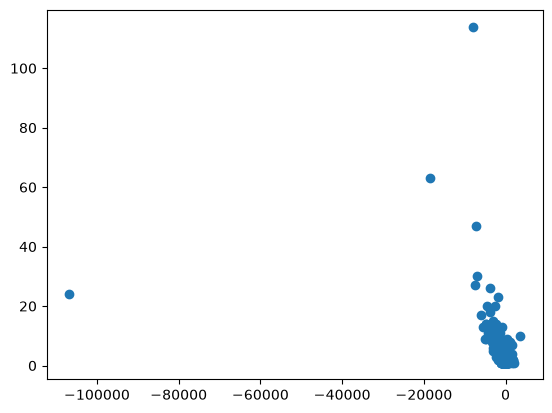

In [ ]:
plt.scatter(closures_with_enrollment['Enrollment_Change'], closures_with_enrollment['ClosuresSince2000'])

In [ ]:
closures_with_enrollment.to_csv('data/closures_with_enrollment.csv', index=False)

**Quick linear regression**

Regression Equation: y = -0.00x + 1.42
R² Score: 0.52
Mean Squared Error: 26.62


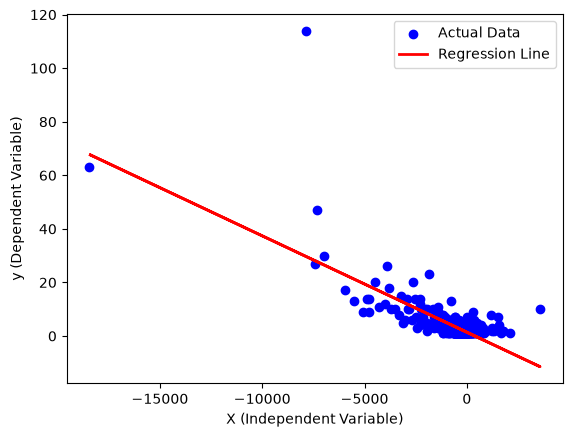

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

#get rid of Detroit
closures_with_enrollment = closures_with_enrollment[closures_with_enrollment['DistrictOfficialName'] != 'Detroit Public Schools Community District']

# 1. Generate sample data (X must be a 2D array/matrix)
X = closures_with_enrollment['Enrollment_Change'].values.reshape(-1, 1)
y = closures_with_enrollment['ClosuresSince2000'].values

# 2. Initialize the model
model = LinearRegression()

# 3. Train the model using the training data
model.fit(X, y)

# 4. Make predictions
y_pred = model.predict(X)

# 5. Extract model parameters
slope = model.coef_[0]
intercept = model.intercept_

print(f"Regression Equation: y = {slope:.2f}x + {intercept:.2f}")
print(f"R² Score: {r2_score(y, y_pred):.2f}")
print(f"Mean Squared Error: {mean_squared_error(y, y_pred):.2f}")

# 6. Plot the results
plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, y_pred, color="red", linewidth=2, label="Regression Line")
plt.xlabel("X (Independent Variable)")
plt.ylabel("y (Dependent Variable)")
plt.legend()
plt.show()

The outlier here is Detroit -> even though DPSCD has closed the most schools, it has actually closed fewer schools than would be predicted based on how many studentsit has lost. When you get rid of Detroit, the closures 